In [1]:
import os
import zipfile
import urllib.request

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
zip_path = "/content/online_retail.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_file:
    print(zip_file.namelist())
    zip_file.extract("Online Retail.xlsx", "/content")

print("Dataset downloaded and extracted successfully!")

['Online Retail.xlsx']
Dataset downloaded and extracted successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
file_path = "/content/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# First five records
print("\nFirst five rows:")
display(df.head())

# Data types and non-null counts
print("\nDataset information:")
df.info()

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
# 1. Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# 2. Count duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# 3. Check negative, zero, and positive quantities
print("\nQuantity categories:")
print("Negative:", (df["Quantity"] < 0).sum())
print("Zero:", (df["Quantity"] == 0).sum())
print("Positive:", (df["Quantity"] > 0).sum())

# 4. Check zero, negative, and positive prices
print("\nPrice categories:")
print("Negative:", (df["UnitPrice"] < 0).sum())
print("Zero:", (df["UnitPrice"] == 0).sum())
print("Positive:", (df["UnitPrice"] > 0).sum())

# 5. Inspect cancellation invoice numbers
print("\nCancellation invoice count:")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows:
5268

Quantity categories:
Negative: 10624
Zero: 0
Positive: 531285

Price categories:
Negative: 2
Zero: 2515
Positive: 539392

Cancellation invoice count:
9288


In [6]:
# 1. Inspect duplicate rows
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicates))
display(duplicates.head(10))

# 2. Inspect negative quantities
print("\nExamples of negative quantities:")
display(df[df["Quantity"] < 0].head(10))

# 3. Inspect negative prices
print("\nRows with negative prices:")
display(df[df["UnitPrice"] < 0])

# 4. Inspect zero-price transactions
print("\nExamples of zero-price rows:")
display(df[df["UnitPrice"] == 0].head(10))

# 5. Inspect missing product descriptions
print("\nRows with missing descriptions:")
display(df[df["Description"].isna()].head(10))

# 6. Check unique cancellation invoices
cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print(
    "\nUnique cancellation invoice numbers:",
    cancellations["InvoiceNo"].nunique()
)

Rows involved in duplicates: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom



Examples of negative quantities:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



Rows with negative prices:


...


Examples of zero-price rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



Rows with missing descriptions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



Unique cancellation invoice numbers: 3836


In [7]:
# Create a separate working copy
retail = df.copy()

# Record the original number of rows
print("Original rows:", len(df))
print("Working copy rows:", len(retail))

# Count exact duplicate occurrences
print("Exact duplicate occurrences:", retail.duplicated().sum())

Original rows: 541909
Working copy rows: 541909
Exact duplicate occurrences: 5268


In [8]:
# Examine invoice-level duplication patterns
duplicate_rows = retail[retail.duplicated(keep=False)]

invoice_duplicate_summary = (
    duplicate_rows
    .groupby("InvoiceNo")
    .size()
    .sort_values(ascending=False)
)

print("Invoices containing rows involved in duplicates:")
display(invoice_duplicate_summary.head(10))

Invoices containing rows involved in duplicates:


,0
InvoiceNo,
547651,57
579458,53
577482,52
572103,50
574481,49
552285,48
537781,47
555524,40
575117,40


In [9]:
# Count zero-price rows with and without descriptions
zero_price_summary = (
    retail[retail["UnitPrice"] == 0]
    .assign(DescriptionMissing=lambda x: x["Description"].isna())
    .groupby("DescriptionMissing")
    .size()
)

print("Zero-price rows by description availability:")
display(zero_price_summary)

# Check the most common descriptions among zero-price rows
print("\nMost common descriptions for zero-price rows:")
display(
    retail.loc[
        retail["UnitPrice"] == 0,
        "Description"
    ].value_counts(dropna=False).head(10)
)

Zero-price rows by description availability:


,0
DescriptionMissing,
False,1061
True,1454



Most common descriptions for zero-price rows:


,count
Description,
NaN,1454
check,159
?,47
damages,45
damaged,43
found,25
sold as set on dotcom,20
adjustment,16
Damaged,14


In [10]:
# Inspect every negative-price transaction
negative_price_rows = retail[retail["UnitPrice"] < 0]

display(negative_price_rows)

# Keep a count for our data-quality report
print("Negative-price rows:", len(negative_price_rows))
print(
    "Negative-price descriptions:",
    negative_price_rows["Description"].value_counts(dropna=False).to_dict()
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Negative-price rows: 2
Negative-price descriptions: {'Adjust bad debt': 2}


In [11]:
# Show examples of rows that belong to exact-duplicate groups
exact_duplicates = retail[
    retail.duplicated(keep=False)
].sort_values(["InvoiceNo", "StockCode", "InvoiceDate"])

display(exact_duplicates.head(15))

print("Extra duplicate occurrences:", retail.duplicated().sum())
print("Rows involved in duplicate groups:", len(exact_duplicates))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


Extra duplicate occurrences: 5268
Rows involved in duplicate groups: 10147


In [12]:
# Check whether cancellation invoices have negative quantities
is_cancellation = retail["InvoiceNo"].astype(str).str.startswith("C")
is_negative_quantity = retail["Quantity"] < 0

print("Cancellation invoice rows:", is_cancellation.sum())
print("Negative-quantity rows:", is_negative_quantity.sum())

print("\nCancellation and quantity comparison:")
display(pd.crosstab(
    is_cancellation,
    is_negative_quantity,
    rownames=["Invoice starts with C"],
    colnames=["Quantity is negative"]
))

# Check the quantity patterns among zero-price records
zero_price_rows = retail[retail["UnitPrice"] == 0]

print("\nQuantity patterns among zero-price rows:")
display(zero_price_rows["Quantity"].value_counts().sort_index())

print("\nExamples of zero-price records with descriptions:")
display(
    zero_price_rows[zero_price_rows["Description"].notna()]
    [["InvoiceNo", "StockCode", "Description", "Quantity",
      "InvoiceDate", "CustomerID", "Country"]]
    .head(10)
)

Cancellation invoice rows: 9288
Negative-quantity rows: 10624

Cancellation and quantity comparison:


Quantity is negative,False,True
Invoice starts with C,,
False,531285,1336
True,0,9288



Quantity patterns among zero-price rows:


,count
Quantity,
-9600,2
-9058,1
-5368,1
-4830,1
-3667,1
...,...
3000,1
3100,1
4000,1



Examples of zero-price records with descriptions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,CustomerID,Country
6391,536941,22734,amazon,20,2010-12-03 12:08:00,NaN,United Kingdom
6392,536942,22139,amazon,15,2010-12-03 12:08:00,NaN,United Kingdom
7313,537032,21275,?,-30,2010-12-03 16:50:00,NaN,United Kingdom
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,12647.0,Germany
13217,537425,84968F,check,-20,2010-12-06 15:35:00,NaN,United Kingdom
13218,537426,84968E,check,-35,2010-12-06 15:36:00,NaN,United Kingdom
13264,537432,35833G,damages,-43,2010-12-06 16:10:00,NaN,United Kingdom
14335,537534,85064,CREAM SWEETHEART LETTER RACK,1,2010-12-07 11:48:00,NaN,United Kingdom
14336,537534,84832,ZINC WILLIE WINKIE CANDLE STICK,1,2010-12-07 11:48:00,NaN,United Kingdom
14337,537534,84692,BOX OF 24 COCKTAIL PARASOLS,2,2010-12-07 11:48:00,NaN,United Kingdom


In [13]:
# Count zero-price records by description
zero_price_descriptions = (
    retail.loc[retail["UnitPrice"] == 0, "Description"]
    .value_counts(dropna=False)
)

display(zero_price_descriptions.head(30))

# Check descriptions and quantities for zero-price rows
zero_price_rows = retail[retail["UnitPrice"] == 0]

print("Total zero-price rows:", len(zero_price_rows))
print(
    "Positive quantity:",
    (zero_price_rows["Quantity"] > 0).sum()
)
print(
    "Negative quantity:",
    (zero_price_rows["Quantity"] < 0).sum()
)

# Check missing customer IDs
print(
    "Missing CustomerID:",
    zero_price_rows["CustomerID"].isna().sum()
)

,count
Description,
NaN,1454
check,159
?,47
damages,45
damaged,43
found,25
sold as set on dotcom,20
adjustment,16
Damaged,14


Total zero-price rows: 2515
Positive quantity: 1179
Negative quantity: 1336
Missing CustomerID: 2475


In [14]:
# Keep the original df unchanged
retail_clean = df.drop_duplicates().copy()

# Standardize column names only if needed
retail_clean.columns = retail_clean.columns.str.strip()

# Identify special transaction types
retail_clean["IsCancellationInvoice"] = (
    retail_clean["InvoiceNo"].astype(str).str.startswith("C")
)

retail_clean["IsNegativeQuantity"] = (
    retail_clean["Quantity"] < 0
)

retail_clean["IsZeroPrice"] = (
    retail_clean["UnitPrice"] == 0
)

retail_clean["IsAccountingAdjustment"] = (
    retail_clean["Description"]
    .fillna("")
    .str.strip()
    .str.lower()
    .eq("adjust bad debt")
)

# Calculate transaction value
retail_clean["Revenue"] = (
    retail_clean["Quantity"] * retail_clean["UnitPrice"]
)

# Review the result
print("Original rows:", len(df))
print("Rows after exact duplicate removal:", len(retail_clean))
print("Rows removed:", len(df) - len(retail_clean))

print("\nMissing values after duplicate removal:")
display(retail_clean.isna().sum())

print("\nTransaction flags:")
print("Cancellation invoice rows:",
      retail_clean["IsCancellationInvoice"].sum())
print("Negative quantity rows:",
      retail_clean["IsNegativeQuantity"].sum())
print("Zero-price rows:",
      retail_clean["IsZeroPrice"].sum())
print("Accounting adjustment rows:",
      retail_clean["IsAccountingAdjustment"].sum())

Original rows: 541909
Rows after exact duplicate removal: 536641
Rows removed: 5268

Missing values after duplicate removal:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135037
Country,0
IsCancellationInvoice,0
IsNegativeQuantity,0



Transaction flags:
Cancellation invoice rows: 9251
Negative quantity rows: 10587
Zero-price rows: 2510
Accounting adjustment rows: 3


In [15]:
adjustment_rows = retail_clean[
    retail_clean["IsAccountingAdjustment"]
]

display(adjustment_rows)

print("Adjustment rows:", len(adjustment_rows))
print("Negative-price adjustment rows:",
      (adjustment_rows["UnitPrice"] < 0).sum())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellationInvoice,IsNegativeQuantity,IsZeroPrice,IsAccountingAdjustment,Revenue
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,False,False,False,True,11062.06
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,False,False,False,True,-11062.06
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,False,False,False,True,-11062.06


Adjustment rows: 3
Negative-price adjustment rows: 2


In [16]:
# Create a separate dataset for ordinary product-sales analysis
sales = retail_clean[
    (~retail_clean["IsAccountingAdjustment"]) &
    (retail_clean["UnitPrice"] > 0) &
    (retail_clean["Quantity"] > 0) &
    (~retail_clean["IsCancellationInvoice"])
].copy()

# Check the results
print("Cleaned dataset rows:", len(retail_clean))
print("Ordinary sales rows:", len(sales))
print("Total revenue:", round(sales["Revenue"].sum(), 2))
print("Missing customer IDs:", sales["CustomerID"].isna().sum())

display(sales.head())

Cleaned dataset rows: 536641
Ordinary sales rows: 524877
Total revenue: 10631048.74
Missing customer IDs: 132185


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellationInvoice,IsNegativeQuantity,IsZeroPrice,IsAccountingAdjustment,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,False,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,False,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,False,20.34


In [17]:
# Make sure InvoiceDate is datetime
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

# Extract year and month
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    sales.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

# Convert YearMonth to string for plotting
monthly_sales["YearMonth"] = monthly_sales["YearMonth"].astype(str)

display(monthly_sales)

,YearMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,746779.320
9,2011-09,1056435.192


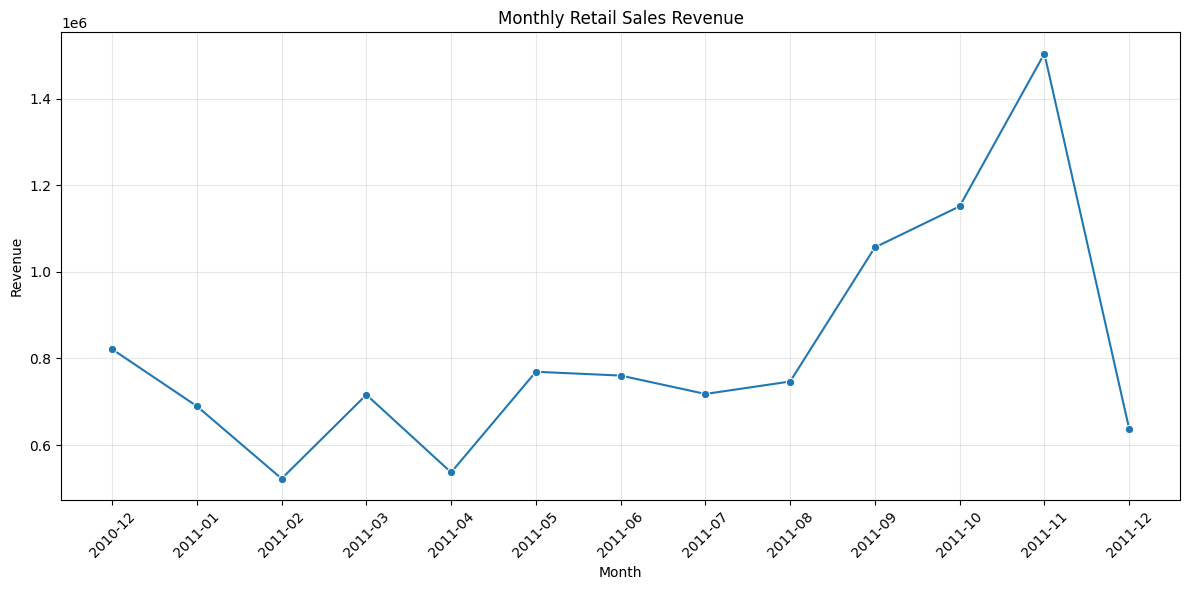

In [18]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Retail Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
best_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmax()
]

weakest_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmin()
]

print("Highest-revenue month:")
print(best_month)

print("\nLowest-revenue month:")
print(weakest_month)

Highest-revenue month:
YearMonth       2011-11
Revenue      1503866.78
Name: 11, dtype: object

Lowest-revenue month:
YearMonth      2011-02
Revenue      522545.56
Name: 2, dtype: object


In [20]:
# Top 10 products by recorded revenue
product_sales = (
    sales.dropna(subset=["Description"])
    .groupby("Description", as_index=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Transactions=("InvoiceNo", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
)

top_10_products = product_sales.head(10)

display(top_10_products)

,Description,TotalRevenue,UnitsSold,Transactions
1066,DOTCOM POSTAGE,206248.77,706,706
2852,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2386,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3843,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,2256
2412,PARTY BUNTING,99445.23,18283,1685
1815,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
2051,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
2691,POSTAGE,78101.88,3150,1126
2191,Manual,77752.82,6985,290
2740,RABBIT NIGHT LIGHT,66870.03,30739,994


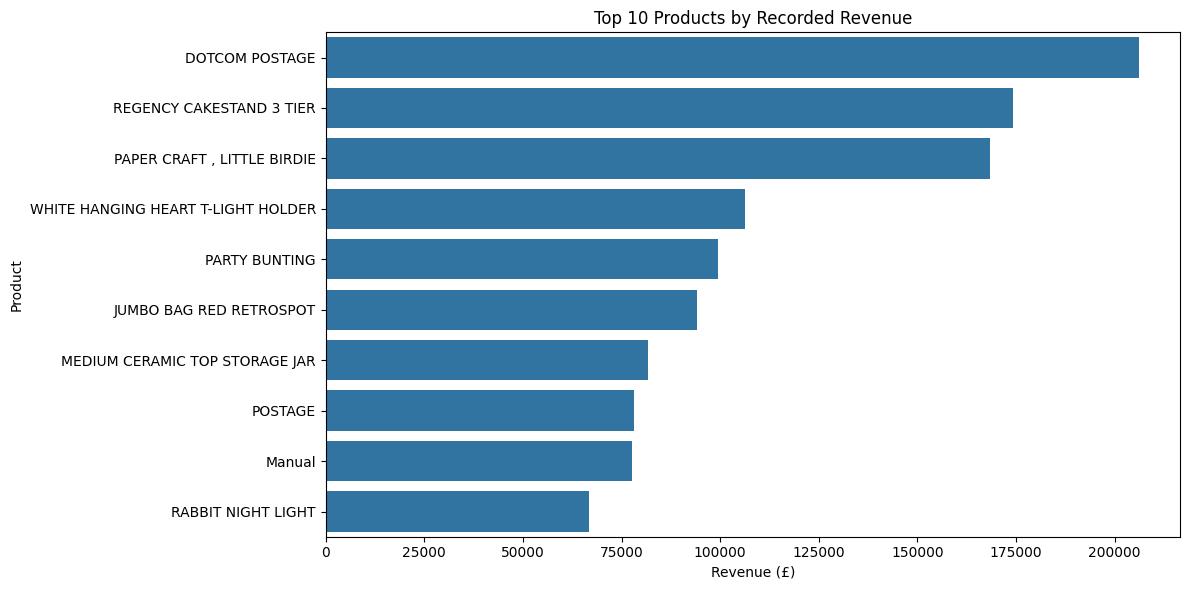

In [21]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_products,
    x="TotalRevenue",
    y="Description"
)

plt.title("Top 10 Products by Recorded Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [22]:
# Inspect the unusually high quantity for PAPER CRAFT, LITTLE BIRDIE
display(
    sales.loc[
        sales["Description"].eq("PAPER CRAFT, LITTLE BIRDIE"),
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country",
            "Revenue"
        ]
    ]
)

# Identify common service or administrative descriptions
service_keywords = r"POSTAGE|MANUAL|DOTCOM|ADJUSTMENT|BANK CHARGES"

service_rows = sales[
    sales["Description"].str.contains(
        service_keywords,
        case=False,
        na=False
    )
]

print("Rows matching service/admin keywords:", len(service_rows))
display(
    service_rows.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue


Rows matching service/admin keywords: 2200


,Revenue
Description,
DOTCOM POSTAGE,206248.770
POSTAGE,78101.880
Manual,77752.820
Dotcomgiftshop Gift Voucher £30.00,175.530
Dotcomgiftshop Gift Voucher £50.00,167.560
Dotcomgiftshop Gift Voucher £20.00,167.050
Bank Charges,165.001
Dotcomgiftshop Gift Voucher £40.00,100.700
Dotcomgiftshop Gift Voucher £100.00,83.330


In [23]:
# Check the exact description and quantity
paper_craft = sales[
    sales["Description"].str.contains(
        "PAPER CRAFT",
        case=False,
        na=False
    )
]

display(
    paper_craft[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue"]
    ].head(20)
)

print("Matching rows:", len(paper_craft))
print("Total units:", paper_craft["Quantity"].sum())

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6


Matching rows: 1
Total units: 80995


In [24]:
# Exclude clearly non-product descriptions for this ranking
non_product_pattern = (
    r"POSTAGE|^MANUAL$|^BANK CHARGES$|"
    r"^ADJUST BAD DEBT$|^DOTCOMGIFTSHOP GIFT VOUCHER"
)

physical_sales = sales[
    ~sales["Description"].str.contains(
        non_product_pattern,
        case=False,
        na=False,
        regex=True
    )
].copy()

product_ranking = (
    physical_sales.dropna(subset=["Description"])
    .groupby(["StockCode", "Description"], as_index=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
)

display(product_ranking.head(10))

,StockCode,Description,TotalRevenue,UnitsSold,InvoiceCount
1261,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2589,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3772,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
2668,47566,PARTY BUNTING,99445.23,18283,1685
3760,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
2044,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
1950,23084,RABBIT NIGHT LIGHT,66870.03,30739,994
943,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160
2874,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
2736,79321,CHILLI LIGHTS,54096.36,10302,661


In [25]:
# Inspect every line on the unusual invoice
display(
    retail_clean[
        retail_clean["InvoiceNo"].astype(str) == "581483"
    ].sort_values("StockCode")
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellationInvoice,IsNegativeQuantity,IsZeroPrice,IsAccountingAdjustment,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,False,False,False,False,168469.6


In [26]:
# Exclude rows without CustomerID for customer-level analysis
customer_sales = sales.dropna(subset=["CustomerID"]).copy()

# Summarize each customer's purchasing activity
customer_summary = (
    customer_sales.groupby("CustomerID", as_index=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalUnits=("Quantity", "sum"),
        TotalInvoices=("InvoiceNo", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
)

print("Identifiable customers:", customer_summary["CustomerID"].nunique())

print("\nTop 10 customers by recorded revenue:")
display(customer_summary.head(10))

print("\nAverage recorded revenue per identifiable customer:")
print(round(customer_summary["TotalRevenue"].mean(), 2))

Identifiable customers: 4338

Top 10 customers by recorded revenue:


,CustomerID,TotalRevenue,TotalUnits,TotalInvoices
1689,14646.0,280206.02,196915,73
4201,18102.0,259657.30,64124,60
3728,17450.0,194390.79,69973,46
3008,16446.0,168472.50,80997,2
1879,14911.0,143711.17,80240,201
55,12415.0,124914.53,77374,21
1333,14156.0,117210.08,57768,55
3771,17511.0,91062.38,64549,31
2702,16029.0,80850.84,40108,63
0,12346.0,77183.60,74215,1



Average recorded revenue per identifiable customer:
2048.69


In [27]:
# Categorize customers by number of distinct invoices
customer_summary["CustomerType"] = np.where(
    customer_summary["TotalInvoices"] > 1,
    "Repeat customer",
    "One-invoice customer"
)

# Count customers in each group
customer_type_summary = (
    customer_summary.groupby("CustomerType")
    .agg(
        CustomerCount=("CustomerID", "nunique"),
        TotalRevenue=("TotalRevenue", "sum")
    )
    .reset_index()
)

customer_type_summary["CustomerPercentage"] = (
    customer_type_summary["CustomerCount"]
    / customer_summary["CustomerID"].nunique()
    * 100
).round(2)

display(customer_type_summary)

,CustomerType,CustomerCount,TotalRevenue,CustomerPercentage
0,One-invoice customer,1493,613989.561,34.42
1,Repeat customer,2845,8273219.333,65.58


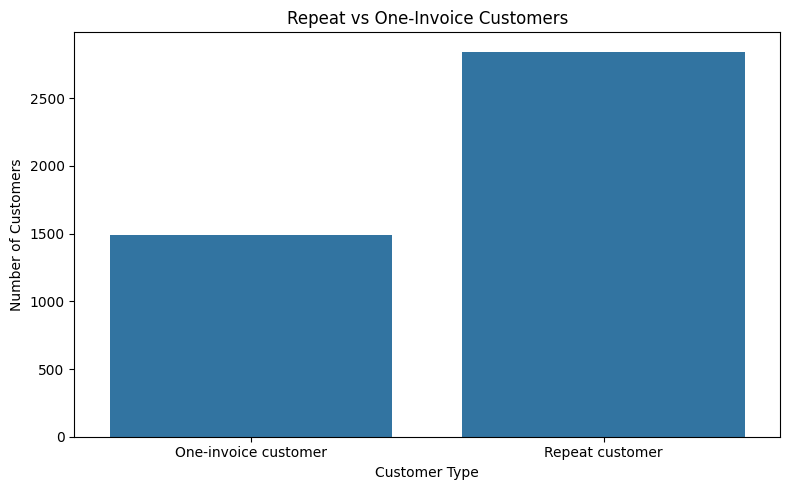

In [28]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=customer_type_summary,
    x="CustomerType",
    y="CustomerCount"
)

plt.title("Repeat vs One-Invoice Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [29]:
# Revenue and customer metrics by country
country_sales = (
    sales.groupby("Country", as_index=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        UniqueCustomers=("CustomerID", "nunique"),
        InvoiceCount=("InvoiceNo", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
)

display(country_sales.head(10))

,Country,TotalRevenue,UnitsSold,UniqueCustomers,InvoiceCount
36,United Kingdom,8990682.034,4646905,3920,18018
24,Netherlands,285446.340,200361,9,94
10,EIRE,283140.520,147007,3,288
14,Germany,228678.400,119154,94,457
13,France,209625.370,112060,87,392
0,Australia,138453.810,83891,9,57
31,Spain,61558.560,27933,30,90
33,Switzerland,57067.600,30617,21,54
3,Belgium,41196.340,23237,25,98
32,Sweden,38367.830,36078,8,36


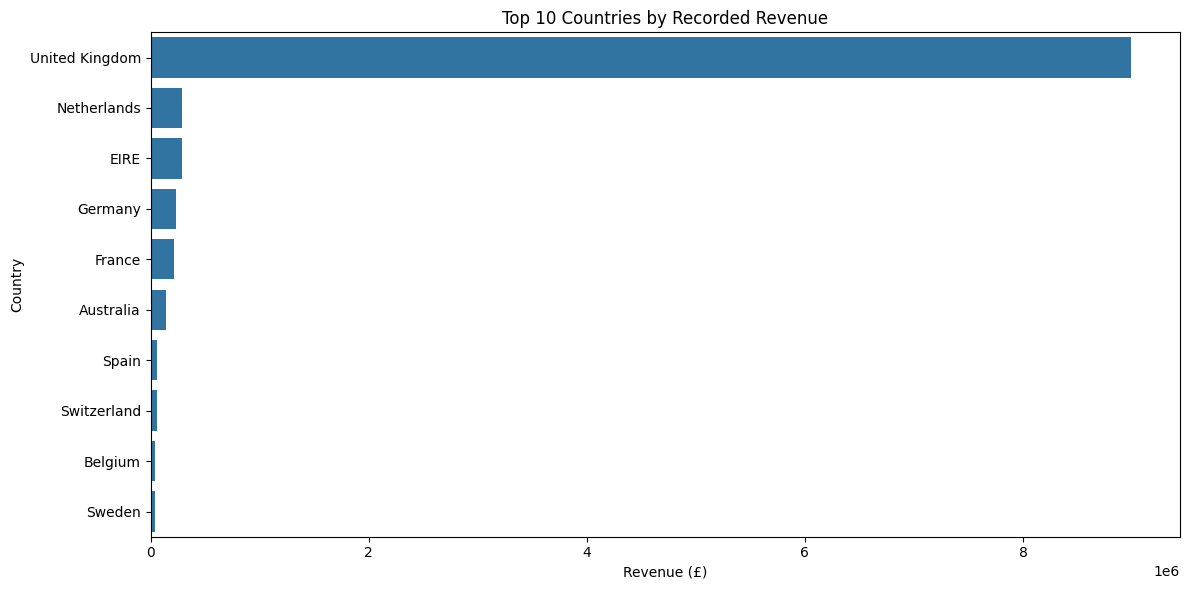

In [30]:
top_10_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_countries,
    x="TotalRevenue",
    y="Country"
)

plt.title("Top 10 Countries by Recorded Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [31]:
# 1. Top 10 identifiable customers' revenue share
total_identified_revenue = customer_summary["TotalRevenue"].sum()

top_10_customer_revenue = (
    customer_summary.head(10)["TotalRevenue"].sum()
)

top_10_share = (
    top_10_customer_revenue / total_identified_revenue
) * 100

print("Identifiable-customer revenue:",
      round(total_identified_revenue, 2))

print("Top 10 customer revenue:",
      round(top_10_customer_revenue, 2))

print("Top 10 customers' revenue share:",
      round(top_10_share, 2), "%")

Identifiable-customer revenue: 8887208.89
Top 10 customer revenue: 1537659.21
Top 10 customers' revenue share: 17.3 %


In [32]:
monthly_sales["RevenueChangePct"] = (
    monthly_sales["Revenue"].pct_change() * 100
).round(2)

display(monthly_sales)

,YearMonth,Revenue,RevenueChangePct
0,2010-12,821452.730,NaN
1,2011-01,689811.610,-16.03
2,2011-02,522545.560,-24.25
3,2011-03,716215.260,37.06
4,2011-04,536968.491,-25.03
5,2011-05,769296.610,43.27
6,2011-06,760547.010,-1.14
7,2011-07,718076.121,-5.58
8,2011-08,746779.320,4.00
9,2011-09,1056435.192,41.47
